In [1]:
import numpy as np
import matplotlib.pyplot as plt
import keras
from keras import layers
import tensorflow as tf
from keras.layers import Dense

In [2]:
data = tf.keras.datasets.fashion_mnist.load_data()
print(type(data))
print(len(data))

<class 'tuple'>
2


In [3]:
print(type(data[0]))
print(type(data[1]))
print(len(data[0]))
print(len(data[1]))

<class 'tuple'>
<class 'tuple'>
2
2


In [4]:
(x_train_full, y_train_full) , (x_test, y_test) = data
print(f"x_train: {x_train_full.shape}, y_train:{y_train_full.shape}, x_test:{x_test.shape}, y_test:{y_test.shape}")

x_train: (60000, 28, 28), y_train:(60000,), x_test:(10000, 28, 28), y_test:(10000,)


In [5]:
print(type(x_train_full))

<class 'numpy.ndarray'>


In [6]:
print(x_train_full.max())
print(x_train_full.min())
print(x_train_full.dtype)

255
0
uint8


#### Normalized

In [ ]:
MAX_PIXEL_VALUE = 255.0
x_train_full = x_train_full.astype("float32") / MAX_PIXEL_VALUE
x_test = x_test.astype("float32") / MAX_PIXEL_VALUE

#### Train\ Validation \ Test

In [8]:
TRAIN_SIZE = 30_000

x_val = x_train_full[TRAIN_SIZE:]
y_val = y_train_full[TRAIN_SIZE:]

x_train = x_train_full[:TRAIN_SIZE]
y_train = y_train_full[:TRAIN_SIZE]

In [9]:
y_train[0]

np.uint8(9)

In [10]:
CLASS_NAMES = ["T-shirt", "Trouser", "Pullover", 
               "Dress", "Coat", "Sandal", "Shirt", 
               "Sneaker", "Bag", "Ankle boot"]

In [11]:
print(f"train: {x_train.shape}, val: {x_val.shape}, test: {x_test.shape}, class: {len(CLASS_NAMES)}")

train: (30000, 28, 28), val: (30000, 28, 28), test: (10000, 28, 28), class: 10


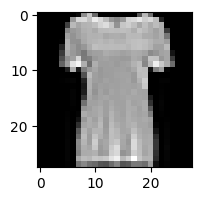

In [12]:
plt.figure(figsize=(2,3))
plt.imshow(x_train[10], cmap="gray")
plt.show()

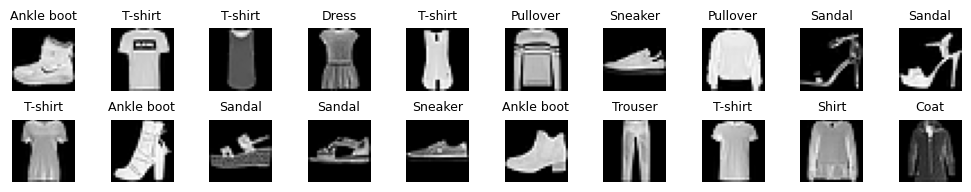

In [13]:
fig, axes = plt.subplots(2, 10, figsize=(10, 2))
for ax, img, label in zip(axes.flat, x_train, y_train):
    ax.imshow(img, cmap= "gray")
    ax.set_title(CLASS_NAMES[label], fontsize= 9)
    ax.axis("off")

plt.tight_layout()
plt.show()

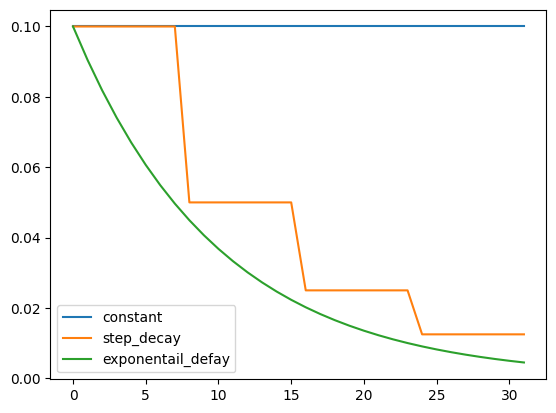

In [14]:
import math
## different LR change functions

def constant(epoch):
    return 0.1


def constant2(epoch):
    return 0.01

def step_decay(epoch):
    return 0.1 * 0.5 **(epoch//8)


def exponentail_defay(epoch):
    return 0.1 * math.exp(-0.1*epoch)


epochs = range(32)
plt.plot(epochs, [constant(epoch) for epoch in epochs], label='constant')
plt.plot(epochs, [step_decay(epoch) for epoch in epochs], label='step_decay')
plt.plot(epochs, [exponentail_defay(epoch) for epoch in epochs], label='exponentail_defay')
plt.legend()
plt.show()

constant: test_accuracy: [110.2044906616211, 0.2558000087738037]
step_decay: test_accuracy: [101.81597137451172, 0.19900000095367432]
exponentail_defay: test_accuracy: [21.187469482421875, 0.26989999413490295]


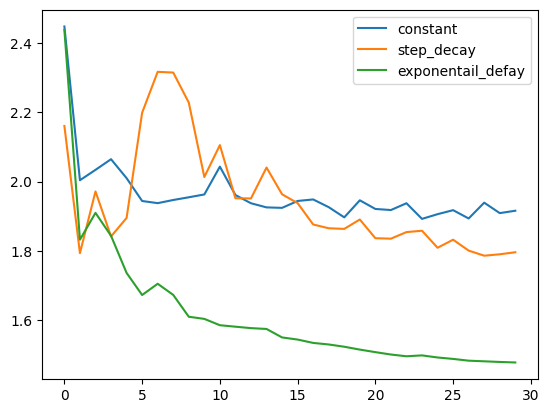

In [15]:
def make_model():
    model = keras.Sequential([
        keras.Input(shape=(28, 28)),
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dense(10, activation='softmax'),
    ])
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

for schedule in [constant, step_decay, exponentail_defay]:
    model = make_model()
    lr_callback = keras.callbacks.LearningRateScheduler(schedule=schedule)
    history = model.fit(x_train, y_train, validation_split=0.2, epochs=30, 
                        batch_size=32, callbacks=[lr_callback], verbose=0)
    print(f"{schedule.__name__}: test_accuracy: {model.evaluate(x_test, y_test, verbose=0)}")
    plt.plot(history.history["loss"], label={schedule.__name__})
    model.save(f"{schedule.__name__}_model.keras")

plt.legend()
plt.show()

In [10]:
constant_model = keras.models.load_model("constant_model.keras")
step_decay_model_model = keras.models.load_model("step_decay_model.keras")
exponentail_defay_model_model = keras.models.load_model("exponentail_defay_model.keras")

print(f"constant_model: test_accuracy: {constant_model.evaluate(x_test, y_test, verbose=0)}")
print(f"step_decay_model_model: test_accuracy: {step_decay_model_model.evaluate(x_test, y_test, verbose=0)}")
print(f"exponentail_defay_model_model: test_accuracy: {exponentail_defay_model_model.evaluate(x_test, y_test, verbose=0)}")

constant_model: test_accuracy: [5.7340288162231445, 0.1842000037431717]
step_decay_model_model: test_accuracy: [248.525146484375, 0.33899998664855957]
exponentail_defay_model_model: test_accuracy: [10.685850143432617, 0.18610000610351562]


### Early stopping

In [ ]:
dense_model1 = keras.Sequential()
dense_model1.add(keras.layers.Input(shape=(28, 28)))
dense_model1.add(keras.layers.Flatten())
dense_model1.add(Dense(64, activation="relu"))
dense_model1.add(Dense(128, activation="relu"))
dense_model1.add(Dense(64, activation="relu"))
dense_model1.add(Dense(32, activation="softmax"))


In [ ]:
dense_model1.compile(
    optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"]
)

In [ ]:
dense_model2 = keras.Sequential()
dense_model2.add(keras.layers.Input(shape=(28, 28)))
dense_model2.add(keras.layers.Flatten())
dense_model2.add(Dense(32, activation="relu"))
dense_model2.add(Dense(128, activation="relu"))
dense_model2.add(Dense(32, activation="relu"))
dense_model2.add(Dense(16, activation="softmax"))

In [ ]:
dense_model2.compile(
    optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"]
    )

In [ ]:
result1 = dense_model1.fit(
    x_train, y_train, 
    validation_split=0.2, epochs=400, batch_size=32)

In [ ]:
result2 = dense_model2.fit(
    x_train, y_train, 
    validation_split=0.2, epochs=400, batch_size=32)

In [ ]:
plt.plot(result1.history["loss"], label="train loss")
plt.plot(result1.history["val_loss"], label="validation loss")
plt.title("model1")
plt.show()

In [ ]:
early_stop1 = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
result1 = dense_model1.fit(x_train, y_train, validation_split=0.2, epochs=400, batch_size=32, callbacks=[early_stop1])

In [ ]:
plt.plot(result1.history["loss"], label="train loss model1")
plt.plot(result1.history["val_loss"], label="validation loss model1")
plt.title("early stop model1")
plt.show()

In [ ]:
early_stop2 = keras.callbacks.EarlyStopping(monitor="val_loss", patience=12, restore_best_weights=True)
result1 = dense_model1.fit(x_train, y_train, validation_split=0.2, epochs=400, batch_size=32, callbacks=[early_stop2])

In [ ]:
plt.plot(result1.history["loss"], label="train loss model1")
plt.plot(result1.history["val_loss"], label="validation loss model1")
plt.title("early stop2 model1")
plt.show()